# 06 · Efficiency / safety trade-off

Notebook 05 reports one operating point. This one sweeps the lever that sets it
and asks the question the clinical framing actually turns on:

> **Where does the compute saving come from?**

A model that saves 60% of its propagation by exiting early on *everyone* is not
the same result as one that saves 60% by exiting early on the patients who are
obviously going to be fine. The first is a compression result. Only the second
is a clinical one.

Two levers, and the open question from HANDOVER §6.3 is whether they are really
distinct:

- **`ponder_cost`** — the price of depth. Risk-weighted, so it only rewards
  shallow exits on `(1 - risk)` mass.
- **`high_risk_halt_penalty`** — discourages shallow halts on high-risk nodes,
  normalised by risk mass so its effective weight does not silently scale with
  the ~11% prevalence.

§6.3's concern: both may act as *global* depth levers, in which case they fight
over the same mean depth instead of separating low- from high-risk cohorts, and
the safety term is selective in name only. The sweep below tests that directly —
if the two levers trace the same path through (depth, safety) space, they are
the same lever wearing two hats.

In [1]:
exec(open("/kaggle/working/clinical-eegnn/notebooks/src/_bootstrap.py").read())
from src import mimic_iv, graph_build as gb
from src.data_prep import make_splits, impute_and_scale
from src.train import set_seed, get_device, train_model
from src.evaluate import evaluate_model, calibrate_on_val
import torch, copy, matplotlib.pyplot as plt

cfg = mimic_cfg()
set_seed(cfg["seed"])
X_raw, y, names, meta = mimic_iv.build_cohort(cfg, verbose=False)
train, val, test = make_splits(y, cfg["seed"])
X = impute_and_scale(X_raw, train)
data = gb.build_graph(X, y, (train, val, test), cfg, meta=meta,
                      cache_dir=CACHE).to(get_device())
print(gb.describe(data))

nodes=17663 edges=426496 avg_degree=24.15 features=542 prevalence={'train': 0.10776635259389877, 'val': 0.10784036666154861, 'test': 0.10784036666154861}


In [2]:
def run_point(**overrides):
    """Train one configuration and return its operating point."""
    c = copy.deepcopy(cfg)
    c["train"].update(overrides)
    set_seed(c["seed"])
    model, _, _ = train_model(data, c, use_exits=True, verbose=False)
    T = calibrate_on_val(model, data)
    r = evaluate_model(model, data, c, split="test", temperature=T)
    return {
        **overrides,
        "test_auroc": r["predictive"]["auroc"],
        "auprc": r["predictive"]["auprc"],
        "ece": r["calibration"]["ece"],
        "avg_depth": r["efficiency"]["avg_exit_depth"],
        "depth_saving_pct": r["efficiency"]["depth_saving_pct"],
        "hi_depth": r["safety"]["high_risk_mean_depth"],
        "lo_depth": r["safety"]["low_risk_mean_depth"],
        "depth_gap": r["safety"]["depth_gap"],
        "hi_miss": r["safety"]["high_risk_miss_rate"],
        "lo_miss": r["safety"]["low_risk_miss_rate"],
        "hi_ece": r["safety"]["high_risk_ece"],
        "ordering_ok": r["safety"]["safety_ordering_ok"],
    }

## Sweep 1 — the price of depth

In [3]:
PONDER = [0.0, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]
rows = []
for pc in PONDER:
    t0 = time.time()
    rows.append(run_point(ponder_cost=pc))
    print(f"  ponder_cost {pc:<6} depth {rows[-1]['avg_depth']:.2f}  "
          f"AUROC {rows[-1]['test_auroc']:.4f}  gap {rows[-1]['depth_gap']:+.2f}  "
          f"[{time.time()-t0:.0f}s]")
sweep_p = pd.DataFrame(rows)
print()
print(sweep_p.round(4).to_string(index=False))

  ponder_cost 0.0    depth 8.13  AUROC 0.8816  gap -2.02  [9s]


  ponder_cost 0.002  depth 9.63  AUROC 0.8872  gap -0.60  [9s]


  ponder_cost 0.005  depth 9.53  AUROC 0.8867  gap -0.58  [9s]


  ponder_cost 0.01   depth 6.30  AUROC 0.8816  gap -0.32  [8s]


  ponder_cost 0.02   depth 4.80  AUROC 0.8819  gap +0.85  [8s]


  ponder_cost 0.05   depth 1.70  AUROC 0.8823  gap +2.26  [8s]


  ponder_cost 0.1    depth 1.00  AUROC 0.8825  gap +0.01  [8s]

 ponder_cost  test_auroc  auprc    ece  avg_depth  depth_saving_pct  hi_depth  lo_depth  depth_gap  hi_miss  lo_miss  hi_ece  ordering_ok
       0.000      0.8816 0.5395 0.1510     8.1285           18.7150    6.3136    8.3306    -2.0170   0.0154   0.1434  0.3005        False
       0.002      0.8872 0.5679 0.1270     9.6346            3.6541    9.0989    9.6942    -0.5954   0.0231   0.1394  0.2617        False
       0.005      0.8867 0.5661 0.1310     9.5347            4.6533    9.0085    9.5933    -0.5848   0.0154   0.1434  0.2664        False
       0.010      0.8816 0.5395 0.1519     6.2992           37.0082    6.0141    6.3309    -0.3168   0.0154   0.1434  0.3008        False
       0.020      0.8819 0.5398 0.1523     4.7985           52.0153    5.5678    4.7128     0.8550   0.0154   0.1434  0.3008         True
       0.050      0.8823 0.5390 0.1531     1.7020           82.9805    3.7345    1.4756     2.2588   0.0154 

## The trade-off curve

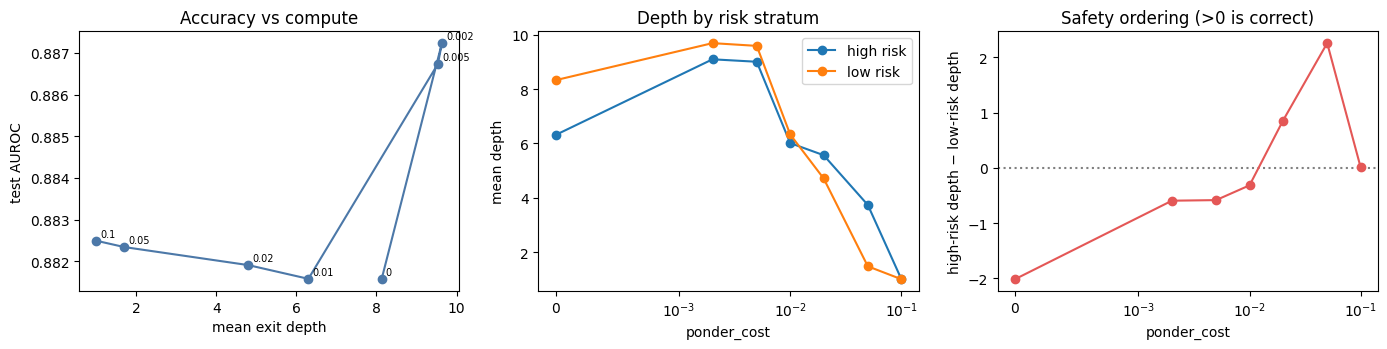

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(sweep_p["avg_depth"], sweep_p["test_auroc"], "o-", color="#4C78A8")
for _, r in sweep_p.iterrows():
    ax[0].annotate(f"{r['ponder_cost']:g}", (r["avg_depth"], r["test_auroc"]),
                   fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[0].set_xlabel("mean exit depth"); ax[0].set_ylabel("test AUROC")
ax[0].set_title("Accuracy vs compute")

ax[1].plot(sweep_p["ponder_cost"], sweep_p["hi_depth"], "o-", label="high risk")
ax[1].plot(sweep_p["ponder_cost"], sweep_p["lo_depth"], "o-", label="low risk")
ax[1].set_xscale("symlog", linthresh=1e-3)
ax[1].set_xlabel("ponder_cost"); ax[1].set_ylabel("mean depth")
ax[1].set_title("Depth by risk stratum"); ax[1].legend()

ax[2].axhline(0, ls=":", c="grey")
ax[2].plot(sweep_p["ponder_cost"], sweep_p["depth_gap"], "o-", color="#E45756")
ax[2].set_xscale("symlog", linthresh=1e-3)
ax[2].set_xlabel("ponder_cost"); ax[2].set_ylabel("high-risk depth − low-risk depth")
ax[2].set_title("Safety ordering (>0 is correct)")
plt.tight_layout(); plt.show()

The middle panel is the one to read. Two curves that **separate** as
`ponder_cost` rises mean the efficiency term is selective: it takes depth away
from low-risk patients and leaves the high-risk ones alone. Two curves that fall
**in parallel** mean it is a global lever, and the "risk-weighted" framing is
not doing what it claims.

## Sweep 2 — is the safety term a separate lever?

If `high_risk_halt_penalty` only moves the mean depth, it is `ponder_cost` with
a different sign, and §6.3's concern is confirmed. If it moves the *gap* while
leaving the mean roughly fixed, it is genuinely selective.

In [5]:
PENALTY = [0.0, 0.01, 0.05, 0.1, 0.25, 0.5]
rows = []
for hp in PENALTY:
    t0 = time.time()
    rows.append(run_point(high_risk_halt_penalty=hp))
    print(f"  halt_penalty {hp:<6} depth {rows[-1]['avg_depth']:.2f}  "
          f"gap {rows[-1]['depth_gap']:+.2f}  AUROC {rows[-1]['test_auroc']:.4f}  "
          f"[{time.time()-t0:.0f}s]")
sweep_h = pd.DataFrame(rows)
print()
print(sweep_h.round(4).to_string(index=False))

  halt_penalty 0.0    depth 1.00  gap +0.00  AUROC 0.8823  [8s]


  halt_penalty 0.01   depth 1.40  gap +1.23  AUROC 0.8823  [8s]


  halt_penalty 0.05   depth 6.30  gap -0.32  AUROC 0.8816  [8s]


  halt_penalty 0.1    depth 9.78  gap -0.55  AUROC 0.8872  [10s]


  halt_penalty 0.25   depth 10.00  gap +0.00  AUROC 0.8893  [11s]


  halt_penalty 0.5    depth 10.00  gap +0.00  AUROC 0.8866  [9s]

 high_risk_halt_penalty  test_auroc  auprc    ece  avg_depth  depth_saving_pct  hi_depth  lo_depth  depth_gap  hi_miss  lo_miss  hi_ece  ordering_ok
                   0.00      0.8823 0.5356 0.1540     1.0000           90.0000    1.0000    1.0000     0.0000   0.0154   0.1434  0.3000        False
                   0.01      0.8823 0.5369 0.1534     1.3991           86.0091    2.5056    1.2759     1.2298   0.0154   0.1434  0.3012         True
                   0.05      0.8816 0.5395 0.1519     6.2992           37.0082    6.0141    6.3309    -0.3168   0.0154   0.1434  0.3008        False
                   0.10      0.8872 0.5723 0.1269     9.7821            2.1795    9.2853    9.8374    -0.5521   0.0231   0.1394  0.2611        False
                   0.25      0.8893 0.5620 0.1435    10.0000            0.0000   10.0000   10.0000     0.0000   0.0308   0.1355  0.2792        False
                   0.50      0.8866 0.55

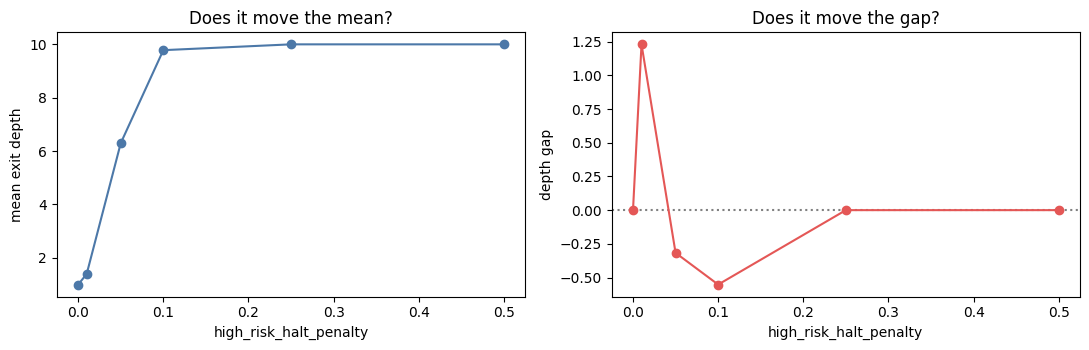

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(sweep_h["high_risk_halt_penalty"], sweep_h["avg_depth"], "o-",
           label="mean depth", color="#4C78A8")
ax[0].set_xlabel("high_risk_halt_penalty"); ax[0].set_ylabel("mean exit depth")
ax[0].set_title("Does it move the mean?")

ax[1].axhline(0, ls=":", c="grey")
ax[1].plot(sweep_h["high_risk_halt_penalty"], sweep_h["depth_gap"], "o-", color="#E45756")
ax[1].set_xlabel("high_risk_halt_penalty"); ax[1].set_ylabel("depth gap")
ax[1].set_title("Does it move the gap?")
plt.tight_layout(); plt.show()

### Separating the two levers

Plotting both sweeps in (mean depth, depth gap) space makes the §6.3 question
visual. If the two sweeps trace the **same curve**, the levers are redundant —
whatever gap you get is a function of mean depth alone, and you cannot buy
safety independently of compute.

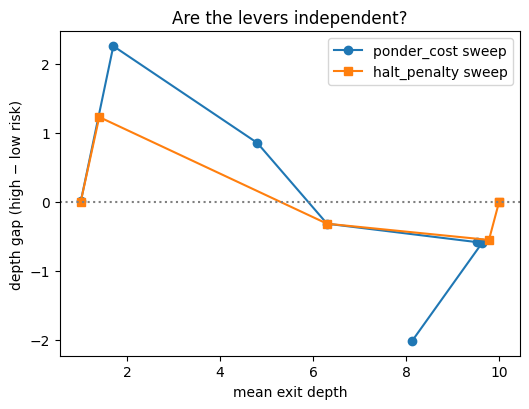

In [7]:
fig, ax = plt.subplots(figsize=(5.4, 4.2))
ax.plot(sweep_p["avg_depth"], sweep_p["depth_gap"], "o-", label="ponder_cost sweep")
ax.plot(sweep_h["avg_depth"], sweep_h["depth_gap"], "s-", label="halt_penalty sweep")
ax.axhline(0, ls=":", c="grey")
ax.set_xlabel("mean exit depth"); ax.set_ylabel("depth gap (high − low risk)")
ax.set_title("Are the levers independent?"); ax.legend()
plt.tight_layout(); plt.show()

## Safety at fixed compute

The clinically meaningful comparison holds compute constant and asks who pays
for it. For each sweep point at a comparable mean depth, the high-risk miss
rate is now a real number that varies with the model — it is no longer pinned to
`1 − operating_sensitivity` by construction.

In [8]:
both = pd.concat([sweep_p.assign(sweep="ponder_cost"),
                  sweep_h.assign(sweep="halt_penalty")], ignore_index=True)
print(both[["sweep", "avg_depth", "test_auroc", "hi_miss", "lo_miss",
            "hi_ece", "depth_gap", "ordering_ok"]].round(4).to_string(index=False))

print("\npoints with correct safety ordering: "
      f"{int(both['ordering_ok'].sum())}/{len(both)}")
if both["hi_miss"].notna().any():
    print(f"high-risk miss rate range: {both['hi_miss'].min():.4f} – "
          f"{both['hi_miss'].max():.4f}")
    print("(a range, not a constant, is the point — the old metric was fixed at "
          "1 − operating_sensitivity for every configuration)")

       sweep  avg_depth  test_auroc  hi_miss  lo_miss  hi_ece  depth_gap  ordering_ok
 ponder_cost     8.1285      0.8816   0.0154   0.1434  0.3005    -2.0170        False
 ponder_cost     9.6346      0.8872   0.0231   0.1394  0.2617    -0.5954        False
 ponder_cost     9.5347      0.8867   0.0154   0.1434  0.2664    -0.5848        False
 ponder_cost     6.2992      0.8816   0.0154   0.1434  0.3008    -0.3168        False
 ponder_cost     4.7985      0.8819   0.0154   0.1434  0.3008     0.8550         True
 ponder_cost     1.7020      0.8823   0.0154   0.1434  0.3008     2.2588         True
 ponder_cost     1.0028      0.8825   0.0154   0.1434  0.2984     0.0094         True
halt_penalty     1.0000      0.8823   0.0154   0.1434  0.3000     0.0000        False
halt_penalty     1.3991      0.8823   0.0154   0.1434  0.3012     1.2298         True
halt_penalty     6.2992      0.8816   0.0154   0.1434  0.3008    -0.3168        False
halt_penalty     9.7821      0.8872   0.0231   0.1394 

In [9]:
json.dump({"ponder_sweep": sweep_p.to_dict("records"),
           "penalty_sweep": sweep_h.to_dict("records")},
          open(f"{CACHE}/sweep_results.json", "w"), indent=2, default=float)
print("wrote sweep_results.json")

wrote sweep_results.json


## What to conclude

- **Curves separate, ordering positive throughout** — the efficiency term is
  selective, and the headline claim ("saves compute on the easy patients, keeps
  depth for the sick") is supported.
- **Curves parallel, ordering positive only at high penalty** — the safety term
  works but only by making everything deeper, which is not a saving.
- **Ordering negative anywhere in the usable range** — the loss is cutting the
  sick short, and `losses.multi_exit_loss` needs the rework described in
  HANDOVER §6.3 before any clinical claim is made.

**Next:** `07_interpretability` — SHAP, attention, and whether exit depth tracks
a clinically sensible notion of difficulty.